# Likelihood of one observation from a Beta distribution

The distribution $\text{Beta}(\theta, 1)$ has density

$$
f(x;\theta)=\theta x^{\theta-1},\qquad 0<x<1,\quad\theta>0.
$$

With one observation $x$, the likelihood is the same expression seen as a function of $\theta$, $L(\theta)=\theta x^{\theta-1}$. We plot it for $x=0.3$ and look at how it changes with the observation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from ipywidgets import interact, FloatSlider

In [2]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
opt_color   = '#E69F00'

## The likelihood

In [3]:
def likelihood(theta, x):
    return theta * x**(theta-1)

The derivative of $\log L(\theta)=\log\theta+(\theta-1)\log x$ is $\frac{1}{\theta}+\log x$, so the maximum likelihood estimator is

$$
\hat\theta=-\frac{1}{\log x}.
$$

In [4]:
def mle(x):
    return -1/np.log(x)

In [5]:
x = 0.3  # The observation
theta = np.linspace(0, 3, 300)

print(mle(x))

0.8305835450825373


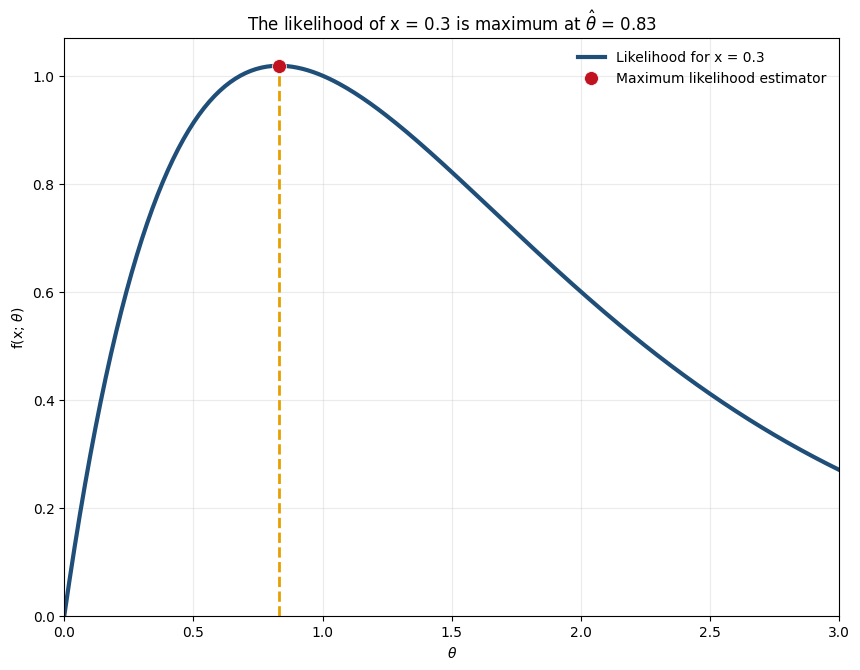

In [6]:
plt.figure(figsize=(10, 7.5))
plt.plot(theta, likelihood(theta, x), color=line_color, lw=3, label=f'Likelihood for x = {x}')
plt.vlines(mle(x), 0, likelihood(mle(x), x), color=opt_color, lw=2, linestyle='--')
plt.plot(mle(x), likelihood(mle(x), x), 'o', color=point_color, markersize=10,
         markeredgecolor='white', markeredgewidth=0.5, label='Maximum likelihood estimator')

plt.xlabel(r'$\theta$')
plt.ylabel(r'f(x; $\theta$)')
plt.xlim(0, 3)
plt.ylim(0, None)
plt.title(rf'The likelihood of x = {x} is maximum at $\hat\theta$ = {mle(x):.2f}')
plt.legend(frameon=False)
plt.grid(True, alpha=0.25)

## The effect of the observation

Move the slider to change the observation. An observation close to 1 is more likely under a large $\theta$, when the density concentrates near 1, and the likelihood becomes flat: one observation says little about a large $\theta$.

In [7]:
def interactive_likelihood(x):
    plt.figure(figsize=(10, 7.5))
    plt.plot(theta, likelihood(theta, x), color=line_color, lw=3, label=f'Likelihood for x = {x:.2f}')
    if mle(x) <= 3:
        plt.plot(mle(x), likelihood(mle(x), x), 'o', color=point_color, markersize=10,
                 markeredgecolor='white', markeredgewidth=0.5, label='Maximum likelihood estimator')
    plt.xlabel(r'$\theta$')
    plt.ylabel(r'f(x; $\theta$)')
    plt.xlim(0, 3)
    plt.ylim(0, None)
    plt.title(rf'x = {x:.2f}: $\hat\theta$ = {mle(x):.2f}')
    plt.legend(frameon=False)
    plt.grid(True, alpha=0.25)
    plt.show()

interact(interactive_likelihood,
         x=FloatSlider(value=x, min=0.05, max=0.95, step=0.05, description='x'));

interactive(children=(FloatSlider(value=0.3, description='x', max=0.95, min=0.05, step=0.05), Output()), _dom_…

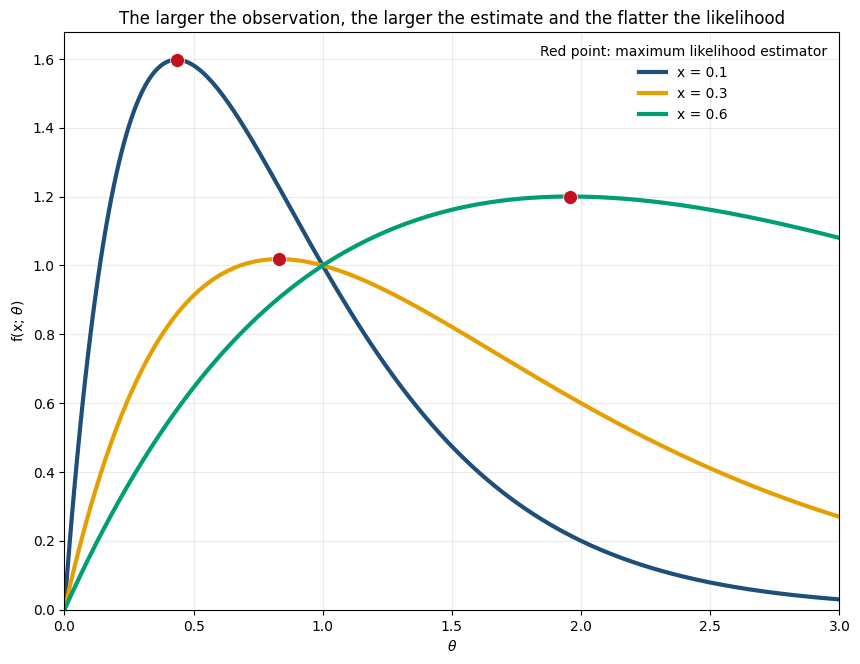

In [8]:
plt.figure(figsize=(10, 7.5))
for obs, color in zip([0.1, 0.3, 0.6], [line_color, opt_color, '#009E73']):
    plt.plot(theta, likelihood(theta, obs), color=color, lw=3, label=f'x = {obs}')
    plt.plot(mle(obs), likelihood(mle(obs), obs), 'o', color=point_color, markersize=10,
             markeredgecolor='white', markeredgewidth=0.5)

plt.xlabel(r'$\theta$')
plt.ylabel(r'f(x; $\theta$)')
plt.xlim(0, 3)
plt.ylim(0, None)
plt.title('The larger the observation, the larger the estimate and the flatter the likelihood')
plt.legend(title='Red point: maximum likelihood estimator', frameon=False)
plt.grid(True, alpha=0.25)